# Análise da diferença de imagens

### Neste exercício utilizaremos o conjunto de dados da FEI + duas fotos inéditas
- Faça o download do conjunto de dados: https://fei.edu.br/~cet/frontalimages_manuallyaligned_part1.zip
- Descompacte o conjunto e dados no mesmo diretório deste arquivo
- Copie as duas imagens inéditas para o mesmo diretório deste arquivo

##### Passo 1: Importar as bibliotecas necessárias

In [48]:
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

##### Passo 2: Importar o conjunto de dados da FEI

In [49]:
# Criando uma variável para armazenar as imagens
dataset = []

# Criando um laço de repetição para importar cada imagem
for file in glob.glob("frontalimages_manuallyaligned_part1/*.jpg"):
    # Carredando a imagem do índice
    load_file = Image.open(file)
    # Convertendo a imagem e tons de cinza
    load_file = load_file.convert("L")
    # Convertendo o objeto imagem em array
    load_file = np.array(load_file)
    # Adicionando a array da na variável dataset
    dataset.append(load_file)
# Convertendo a lista de imagens em array
dataset = np.array(dataset)

In [50]:
# Dimensão do conjunto de dados
dataset.shape

(234, 360, 260)

##### Passo 3: Importar as duas fotos inéditas

In [51]:
foto_neutra = np.array(Image.open("minha_foto_a.jpg").convert("L"))
foto_sorrindo = np.array(Image.open("minha_foto_b.jpg").convert("L"))

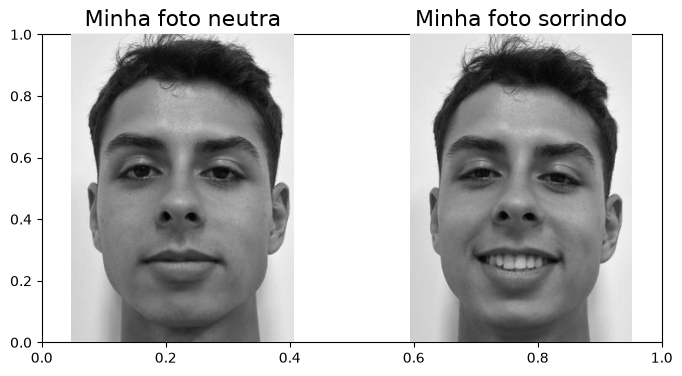

 Dimensões da foto neutra: (360, 260)
Dimensões da foto sorrindo: (360, 260)


In [52]:
plt.subplots(figsize=(8, 4))



# Configurando a visualização da imagem neutra 

plt.subplot(1,2,1)

plt.imshow(foto_neutra, cmap='gray')

plt.title('Minha foto neutra', fontsize=16)

plt.axis('off')



# Configurando a visualização da imagem sorrindo 

plt.subplot(1,2,2)

plt.imshow(foto_sorrindo, cmap='gray')

plt.title('Minha foto sorrindo', fontsize=16)

plt.axis('off')



plt.show()



# Imprime as dimensões das imagens

print(' Dimensões da foto neutra:', foto_neutra.shape)

print('Dimensões da foto sorrindo:', foto_sorrindo.shape)


##### Passo 4: Calcular a diferença das fotos inéditas em relação ao conjunto de dados da FEI

In [53]:

# Obtendo a dimensão do conjunto de imagens
indice = dataset.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_neutral = np.zeros([indice])
dif_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_neutral[img] = np.sum(abs(dataset[img,:,:]-foto_neutra))
    dif_smiling[img] = np.sum(abs(dataset[img,:,:]-foto_sorrindo))

In [54]:
# Convertendo o vetor de diferenças da imagem neutra em DataFrame
df_dif_neutral = pd.DataFrame(dif_neutral, columns = ['Diferença'] )
df_dif_neutral

df_dif_smiling = pd.DataFrame(dif_smiling, columns = ['Diferença'] )
df_dif_smiling

,Diferença
0,14873088.0
1,14881263.0
2,16186438.0
3,16453230.0
4,14035103.0
...,...
229,10584732.0
230,13799856.0
231,12904694.0
232,11123767.0


In [55]:
# Selecionando as imagens com menor diferença da imagem neutra
s_dif_neutral = df_dif_neutral.sort_values(by = 'Diferença').head(5)
s_dif_neutral

s_dif_smiling = df_dif_smiling.sort_values(by = 'Diferença').head(5)
s_dif_smiling

,Diferença
213,0.0
215,6064779.0
214,6960765.0
203,7311438.0
224,7627715.0


In [56]:
# Obtendo o índice das imagens com menor diferença da imagem neutra
id_neutral = list(s_dif_neutral.index)
id_neutral

[212, 214, 215, 224, 203]

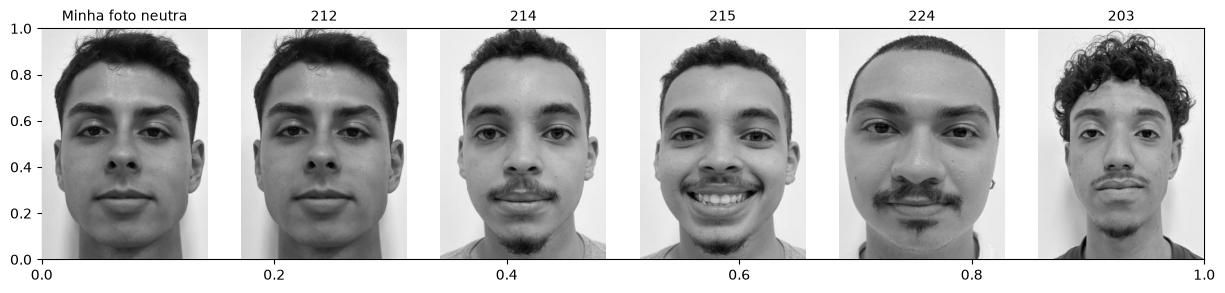

In [57]:
# Visualizando as imagens com menor diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_neutral)+1,1)
plt.imshow(foto_neutra, cmap='gray')
plt.title('Minha foto neutra', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_neutral:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_neutral)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()

#### Repetindo o processo para foto sorrindo...

In [58]:
id_smiling = list(s_dif_smiling.index)
id_smiling

[213, 215, 214, 203, 224]

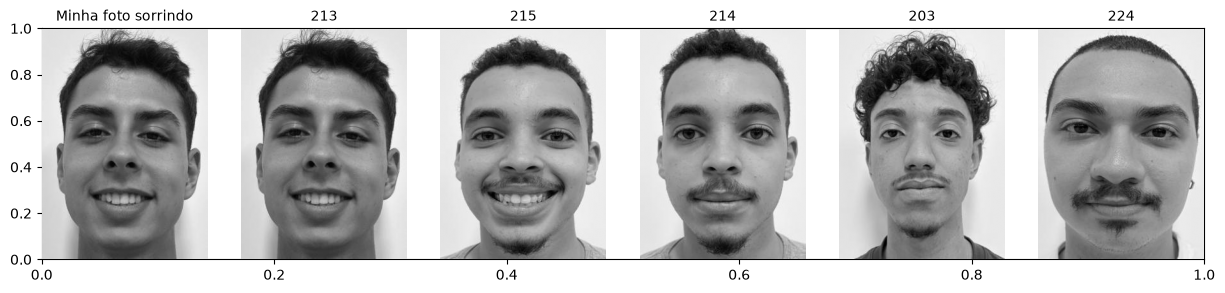

In [59]:
# Visualizando as imagens com maior diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_smiling)+1,1)
plt.imshow(foto_sorrindo, cmap='gray')
plt.title('Minha foto sorrindo', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_smiling:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_smiling)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()

In [60]:
# Selecionando as imagens com menor diferença da imagem neutra
s_dif_neutral_2 = df_dif_neutral.sort_values(by = 'Diferença').tail(5)
s_dif_neutral_2

s_dif_smiling_2 = df_dif_smiling.sort_values(by = 'Diferença').tail(5)
s_dif_smiling_2

,Diferença
101,17110072.0
29,17176553.0
77,17220765.0
28,17380346.0
159,17443007.0


In [61]:
# Obtendo o índice das imagens com menor diferença da imagem neutra
id_neutral_2 = list(s_dif_neutral_2.index)
id_neutral_2

id_smiling_2 = list(s_dif_smiling_2.index)
id_smiling_2

[101, 29, 77, 28, 159]

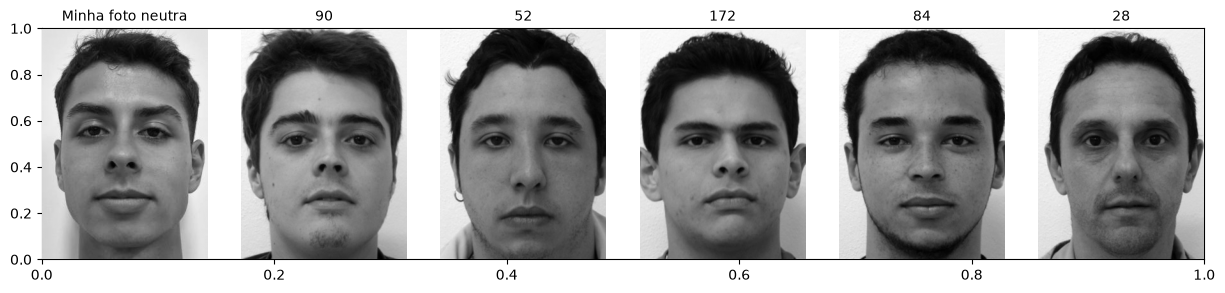

In [62]:
# Visualizando as imagens com menor diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_neutral_2)+1,1)
plt.imshow(foto_neutra, cmap='gray')
plt.title('Minha foto neutra', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_neutral_2:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_neutral_2)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()

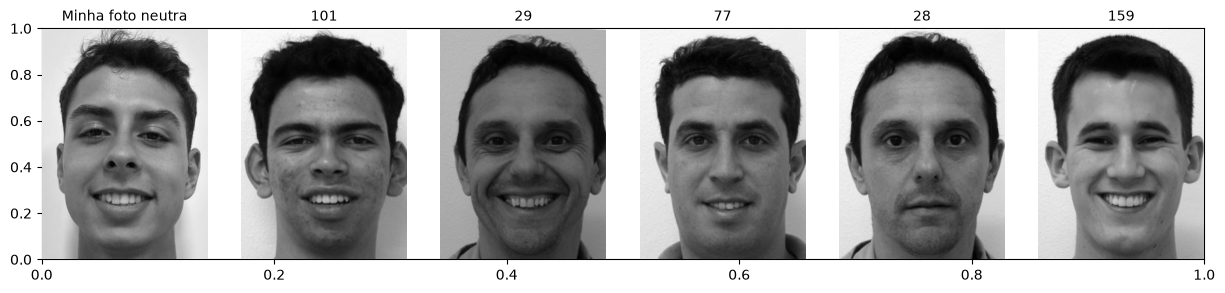

In [63]:
# Visualizando as imagens com maior diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_smiling_2)+1,1)
plt.imshow(foto_sorrindo, cmap='gray')
plt.title('Minha foto neutra', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_smiling_2:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_smiling_2)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()